# Part C — Student collaboration network

Same setup as the network demo: load the two CSVs, build `G` with `from_pandas_edgelist`, and draw it with a force-directed layout. Each question below is a short calculation, then the report and the interpretation.


In [1]:
import os
try:
    from google.colab import files          # available only inside Google Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

NEEDED = ["student_collab_nodes.csv", "student_collab_edges.csv"]
missing = [f for f in NEEDED if not os.path.exists(f)]
if missing and IN_COLAB:
    print("Please upload:", ", ".join(missing))
    files.upload()
missing = [f for f in NEEDED if not os.path.exists(f)]
print("All files ready ✔" if not missing else f"Still missing: {missing}  (re-run this cell)")


All files ready ✔


In [2]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms import community as nxcom

nodes = pd.read_csv("student_collab_nodes.csv")
edges = pd.read_csv("student_collab_edges.csv")
G = nx.from_pandas_edgelist(edges, "Source", "Target", edge_attr="Joint_Projects")
nx.set_node_attributes(G, nodes.set_index("Student")["Home_Org"].to_dict(), "org")
print(G)


Graph with 40 nodes and 86 edges


In [3]:
nodes


,Student,Home_Org,Year_Level
0,Aira,Dev Society,1
1,Ben,Dev Society,3
2,Carlo,Dev Society,2
3,Dana,Dev Society,2
4,Elijah,Dev Society,1
5,Faye,Dev Society,2
6,Gab,Dev Society,3
7,Hannah,Dev Society,1
8,Ivan,Dev Society,4
9,Jasmine,Dev Society,3


In [4]:
edges


,Source,Target,Joint_Projects
0,Aira,Dana,3
1,Aira,Hannah,5
2,Aira,Ivan,4
3,Aira,Noel,1
4,Ben,Elijah,6
...,...,...,...
81,Kat,Mika,5
82,Leo,Mika,8
83,Leo,Franco,6
84,Mika,Noel,5


Density: 0.1103
Connected: True | components: 1
Home_Org
Dev Society           11
Data Science Guild    10
Esports Club          10
Debate Society         9


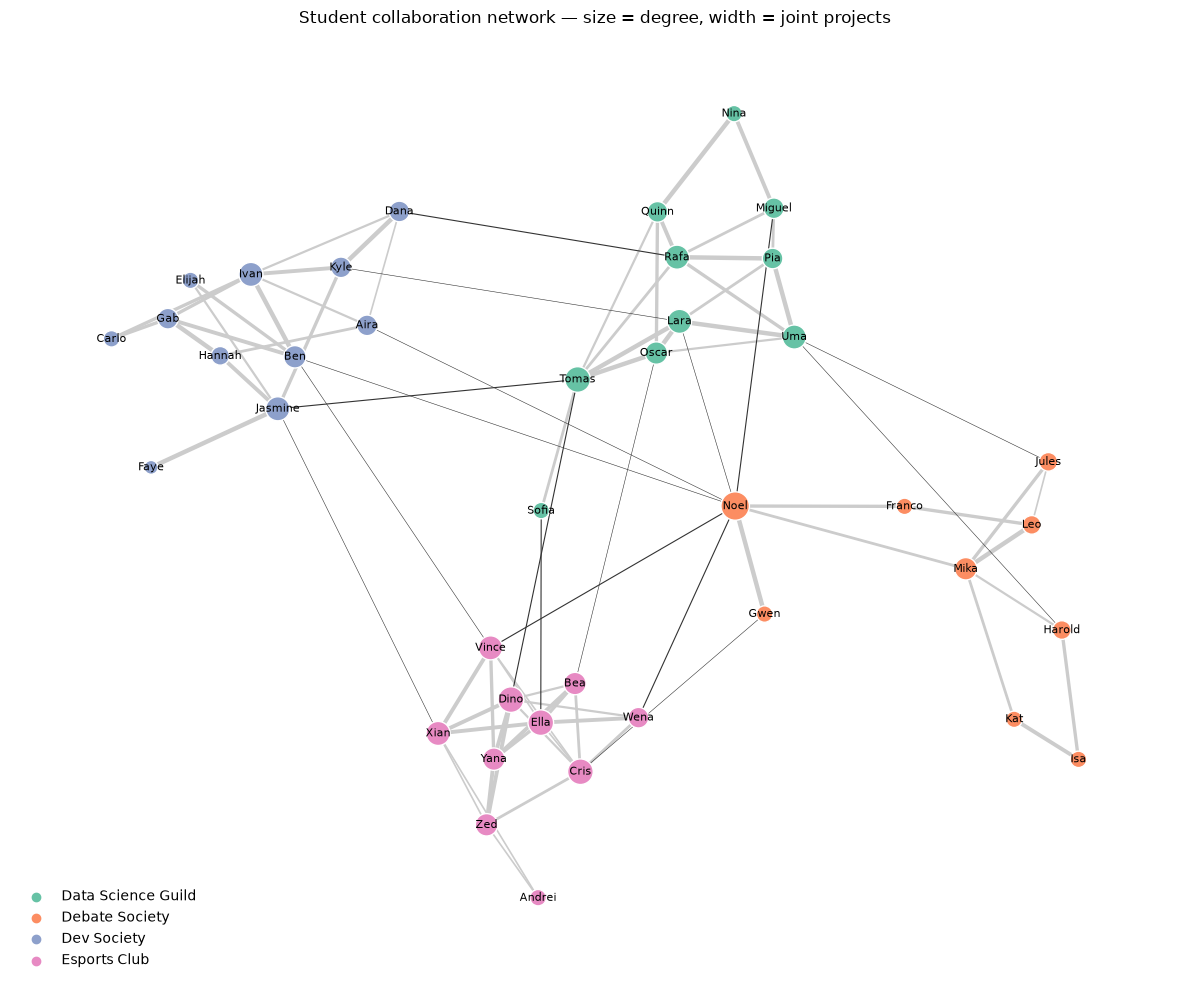

In [5]:
print("Density:", round(nx.density(G), 4))
print("Connected:", nx.is_connected(G), "| components:", nx.number_connected_components(G))
print(nodes["Home_Org"].value_counts().to_string())

org_names = sorted(set(nx.get_node_attributes(G, "org").values()))
palette = plt.cm.Set2.colors
org_color = {name: palette[i] for i, name in enumerate(org_names)}

pos = nx.spring_layout(G, seed=1, k=1.15, weight="Joint_Projects", iterations=100)

def draw_net(graph, pos, title):
    fig, ax = plt.subplots(figsize=(12, 10))
    within = [(u, v) for u, v in graph.edges if graph.nodes[u]["org"] == graph.nodes[v]["org"]]
    cross = [(u, v) for u, v in graph.edges if graph.nodes[u]["org"] != graph.nodes[v]["org"]]
    if within:
        nx.draw_networkx_edges(graph, pos, edgelist=within, ax=ax, edge_color="#ccc",
                               width=[graph[u][v]["Joint_Projects"] * 0.4 for u, v in within])
    if cross:
        nx.draw_networkx_edges(graph, pos, edgelist=cross, ax=ax, edge_color="#333",
                               width=[graph[u][v]["Joint_Projects"] * 0.4 for u, v in cross])
    nx.draw_networkx_nodes(graph, pos, ax=ax,
                           node_size=[60 + 40 * graph.degree(n) for n in graph],
                           node_color=[org_color[graph.nodes[n]["org"]] for n in graph],
                           edgecolors="white")
    nx.draw_networkx_labels(graph, pos, font_size=8, ax=ax)
    for name, color in org_color.items():
        ax.scatter([], [], color=color, label=name)
    ax.legend(loc="lower left", frameon=False)
    ax.set_title(title)
    ax.axis("off")
    plt.tight_layout()
    plt.show()

draw_net(G, pos, "Student collaboration network — size = degree, width = joint projects")


## Q1. Degree distribution

**Manipulate.** Histogram of node degrees.

**Report.** How many students have degree ≤ 3, and what percentage of the class is that? What is the highest degree?

**Interpret.** Describe the shape of the distribution. What does it say about how collaboration is spread across students?


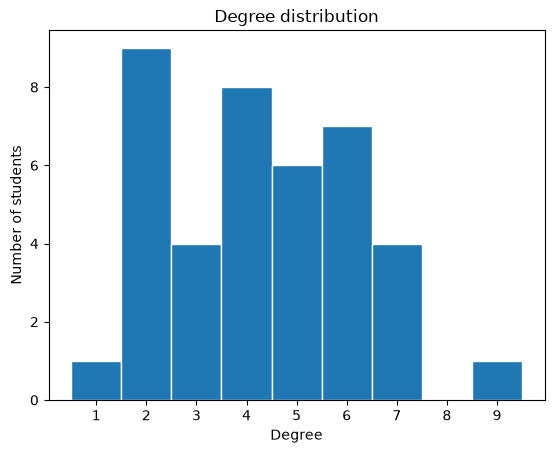

Degree counts: {1: 1, 2: 9, 3: 4, 4: 8, 5: 6, 6: 7, 7: 4, 8: 0, 9: 1}
Degree ≤ 3: 14 students (35% of the class)
Highest degree: 9 (Noel)


In [6]:
deg = dict(G.degree())
plt.hist(deg.values(), bins=range(1, 11), edgecolor="white")
plt.xticks([i + 0.5 for i in range(1, 10)], range(1, 10))
plt.xlabel("Degree")
plt.ylabel("Number of students")
plt.title("Degree distribution")
plt.show()

n = G.number_of_nodes()
low = sum(d <= 3 for d in deg.values())
highest = max(deg.values())
hubs = [name for name, d in deg.items() if d == highest]
print("Degree counts:", {d: sum(v == d for v in deg.values()) for d in range(1, highest + 1)})
print(f"Degree ≤ 3: {low} students ({low / n:.0%} of the class)")
print(f"Highest degree: {highest} ({', '.join(hubs)})")


### Report

**14** students have degree 3 or lower. That is 14/40 = **35%** of the class. The highest degree is **9** (Noel).

### Interpret

The histogram is right-skewed, with a gap rather than a smooth tail. The most common degree is 2 (nine students), and there is a second concentration at degrees 4, 5, and 6. Four students have degree 7, nobody has degree 8, and one student reaches 9.

Collaboration is uneven. About a third of the class works with only one to three partners, while a smaller group carries the wider contact lists. Many students sit in the middle of the range, and Noel is the only student out at the end of the tail.


## Q2. Clustering coefficient

**Manipulate.** Local clustering of every student, and the average.

**Report.** Give the average clustering, Noel's clustering, and the number of students with clustering = 0.

**Interpret.** Noel has the highest degree but one of the lowest clustering values. Explain why this is typical of a broker.


In [7]:
cl = nx.clustering(G)
avg_cl = nx.average_clustering(G)
zero = sorted(name for name, c in cl.items() if c == 0)
print(f"Average clustering: {avg_cl:.4f}")
print(f"Noel's clustering:  {cl['Noel']:.4f}")
print(f"Students with clustering = 0: {len(zero)}")
print(", ".join(zero))

nbrs = list(G.neighbors("Noel"))
print("\nNoel's neighbors:")
for name in sorted(nbrs, key=lambda n: (-G.edges["Noel", n]["Joint_Projects"], n)):
    print(f"  {name:8} {G.nodes[name]['org']:22} joint projects = {G.edges['Noel', name]['Joint_Projects']}")
triangles = [(a, b) for i, a in enumerate(nbrs) for b in nbrs[i + 1:] if G.has_edge(a, b)]
print("Edges among those neighbors:", triangles)
print(f"Check: 2 × {len(triangles)} / (9 × 8) = {2 * len(triangles) / (9 * 8):.4f}")


Average clustering: 0.2290
Noel's clustering:  0.0278
Students with clustering = 0: 11
Elijah, Faye, Franco, Gwen, Hannah, Harold, Isa, Jasmine, Kat, Nina, Sofia

Noel's neighbors:
  Gwen     Debate Society         joint projects = 8
  Franco   Debate Society         joint projects = 6
  Mika     Debate Society         joint projects = 5
  Miguel   Data Science Guild     joint projects = 2
  Vince    Esports Club           joint projects = 2
  Wena     Esports Club           joint projects = 2
  Aira     Dev Society            joint projects = 1
  Ben      Dev Society            joint projects = 1
  Lara     Data Science Guild     joint projects = 1
Edges among those neighbors: [('Ben', 'Vince')]
Check: 2 × 1 / (9 × 8) = 0.0278


### Report

Average clustering is **0.229**. Noel's clustering is **0.0278**. **11** students have clustering 0.

### Interpret

Noel has nine neighbors and only one edge among them, Ben–Vince. Clustering is the share of neighbor pairs who are also linked, so his score is 2 × 1 / (9 × 8) = 1/36 ≈ 0.0278.

Those nine neighbors are spread across all four organizations: Franco, Gwen, and Mika in Debate Society, Aira and Ben in Dev Society, Lara and Miguel in Data Science Guild, and Vince and Wena in Esports Club. They almost never work with each other. A broker's contacts belong to separate groups, so the pairs of neighbors stay unlinked and the clustering score stays low. High degree together with very low clustering is the usual signature of a broker: many ties, few triangles, because the ties reach into circles that do not overlap.


## Q3. Weighted betweenness

**Manipulate.** Store `dist = 1 / Joint_Projects` on each edge, then recompute betweenness with that distance.

**Report.** List the top 3 by weighted betweenness and compare them with the unweighted top 3. Who moved up the most?

**Interpret.** Why must `Joint_Projects` be converted to a distance before computing shortest paths? What would go wrong if you used `Joint_Projects` directly?


In [8]:
for u, v, d in G.edges(data=True):
    d["dist"] = 1 / d["Joint_Projects"]

bc = nx.betweenness_centrality(G)
bcw = nx.betweenness_centrality(G, weight="dist")
cmp = pd.DataFrame({
    "unweighted": bc,
    "weighted": bcw,
    "org": pd.Series(nx.get_node_attributes(G, "org")),
}).round(4)
cmp["rank_u"] = cmp["unweighted"].rank(ascending=False, method="min").astype(int)
cmp["rank_w"] = cmp["weighted"].rank(ascending=False, method="min").astype(int)
cmp["climbed"] = cmp["rank_u"] - cmp["rank_w"]

print("Unweighted top 3:", cmp["unweighted"].nlargest(3).to_dict())
print("Weighted top 3:", cmp["weighted"].nlargest(3).to_dict())
cmp.nlargest(3, "climbed")[["org", "unweighted", "weighted", "rank_u", "rank_w", "climbed"]]


Unweighted top 3: {'Noel': 0.3377, 'Tomas': 0.1376, 'Mika': 0.1345}
Weighted top 3: {'Noel': 0.3252, 'Tomas': 0.2719, 'Mika': 0.2132}


,org,unweighted,weighted,rank_u,rank_w,climbed
Hannah,Dev Society,0.0198,0.0837,24,10,14
Nina,Data Science Guild,0.0025,0.0229,36,22,14
Yana,Esports Club,0.0119,0.0358,30,18,12


### Report

Weighted betweenness, top 3:

1. **Noel** (Debate Society) — 0.325
2. **Tomas** (Data Science Guild) — 0.272
3. **Mika** (Debate Society) — 0.213

The unweighted top 3 is the same three students in the same order: Noel (0.338), Tomas (0.138), Mika (0.134). Nobody in the top 3 changes rank.

Across the full ranking, **Hannah** and **Nina** tie for the largest climb, each up 14 places (Hannah 24th → 10th, Nina 36th → 22nd). Hannah's score rises much more, and she is the one who enters the top 10. Tomas stays 2nd, but his betweenness score increases the most of anyone (0.138 → 0.272).

### Interpret

Betweenness follows shortest paths, and a shortest-path algorithm reads the edge number as a length. `Joint_Projects` is a strength: eight shared projects is a closer working relationship than one. Passed in directly, the eight-project tie would look eight times longer than the one-project tie, so the search would route through the weak ties and avoid the strong ones. Taking the reciprocal, `dist = 1 / Joint_Projects`, turns the strength into a distance, and a stronger collaboration becomes a shorter step.


## Q4. Eigenvector centrality and PageRank

**Manipulate.** Eigenvector centrality, and PageRank weighted by `Joint_Projects`.

**Report.** Give the top 3 for eigenvector centrality. Is Noel among them? Which organization do the top 3 belong to?

**Interpret.** Explain why the most connected person (degree) is not the top by eigenvector centrality. What does eigenvector centrality reward?


In [9]:
ec = nx.eigenvector_centrality(G, max_iter=1000)
pr = nx.pagerank(G, weight="Joint_Projects")
cent = pd.DataFrame({
    "eigenvector": ec,
    "pagerank": pr,
    "degree": dict(G.degree()),
    "org": pd.Series(nx.get_node_attributes(G, "org")),
}).round(4)
print("Eigenvector top 3:", cent["eigenvector"].nlargest(3).to_dict())
print("PageRank top 3:", cent["pagerank"].nlargest(3).to_dict())
print(f"Noel's eigenvector rank: {int(cent['eigenvector'].rank(ascending=False, method='min')['Noel'])}")
cent.nlargest(3, "eigenvector")


Eigenvector top 3: {'Dino': 0.3314, 'Cris': 0.3278, 'Ella': 0.3203}
PageRank top 3: {'Ivan': 0.0406, 'Mika': 0.0399, 'Noel': 0.0362}
Noel's eigenvector rank: 10


,eigenvector,pagerank,degree,org
Dino,0.3314,0.0351,7,Esports Club
Cris,0.3278,0.0274,7,Esports Club
Ella,0.3203,0.0349,7,Esports Club


### Report

Eigenvector centrality, top 3:

1. **Dino** — 0.331
2. **Cris** — 0.328
3. **Ella** — 0.320

Noel is not among them. He ranks 10th, with score 0.216. All three of the leaders belong to the **Esports Club**.

Weighted PageRank ranks Ivan (Dev Society), Mika (Debate Society), and Noel (Debate Society). PageRank does put Noel in its top 3. Eigenvector centrality does not.

### Interpret

Eigenvector centrality scores a student from the scores of the people they are tied to. Degree only counts neighbors. Noel has the most neighbors, but they are spread across the other three organizations and several of them are peripheral, so they contribute little to this score. Dino, Cris, and Ella sit inside the dense Esports group, each tied to other high-scoring Esports students, and those ties reinforce one another. Eigenvector centrality rewards a connection to someone who is already central. On this graph that means sitting in the tight Esports core, rather than being the person who bridges all four clubs.


## Q5. Shortest paths

**Manipulate.** Shortest path, and every shortest path, from Faye to Isa.

**Report.** Give the path length (hops), the number of distinct shortest paths, and the students that appear on every shortest path.

**Interpret.** Do these paths go through Noel? What does this tell you about relying on a single metric to identify all important brokers?


In [10]:
one = nx.shortest_path(G, "Faye", "Isa")
paths = list(nx.all_shortest_paths(G, "Faye", "Isa"))
on_every = set.intersection(*(set(p) for p in paths))

print(f"One shortest path ({len(one) - 1} hops): {' – '.join(one)}")
print(f"Distinct shortest paths: {len(paths)}")
print(f"Path length: {len(paths[0]) - 1} hops")
for p in paths:
    print(" ", " – ".join(p))
print("On every shortest path:", ", ".join(n for n in paths[0] if n in on_every))
print("Through Noel:", any("Noel" in p for p in paths))


One shortest path (6 hops): Faye – Jasmine – Kyle – Lara – Uma – Harold – Isa
Distinct shortest paths: 4
Path length: 6 hops
  Faye – Jasmine – Kyle – Lara – Uma – Harold – Isa
  Faye – Jasmine – Tomas – Lara – Uma – Harold – Isa
  Faye – Jasmine – Tomas – Oscar – Uma – Harold – Isa
  Faye – Jasmine – Tomas – Rafa – Uma – Harold – Isa
On every shortest path: Faye, Jasmine, Uma, Harold, Isa
Through Noel: False


### Report

The path from Faye to Isa is **6 hops**. There are **4** distinct shortest paths. The students on every one of them are **Faye, Jasmine, Uma, Harold, and Isa**.

1. Faye – Jasmine – Kyle – Lara – Uma – Harold – Isa
2. Faye – Jasmine – Tomas – Lara – Uma – Harold – Isa
3. Faye – Jasmine – Tomas – Oscar – Uma – Harold – Isa
4. Faye – Jasmine – Tomas – Rafa – Uma – Harold – Isa

### Interpret

None of the four paths goes through Noel. Every route leaves Dev Society through Jasmine, crosses Data Science Guild through Uma, and enters Debate Society through Harold. Noel leads the class on degree and on betweenness, and he is still off this route. One ranking cannot name every broker. Who matters depends on which two students you are trying to connect.


## Q6. What-if: add a link

**Manipulate.** Copy the graph and add Faye–Isa with `Joint_Projects = 1`.

**Report.** Report the average shortest path length, the diameter, and Noel's betweenness, before and after.

**Interpret.** One new cross-organization tie was added. Explain why it changes the whole network's distances and reduces Noel's betweenness.


In [11]:
def distance_report(graph, label):
    aspl = nx.average_shortest_path_length(graph)
    diam = nx.diameter(graph)
    b = nx.betweenness_centrality(graph)
    print(f"{label}: average shortest path {aspl:.3f}, diameter {diam}, Noel betweenness {b['Noel']:.3f}")

print(f"Faye–Isa distance before the new edge: {nx.shortest_path_length(G, 'Faye', 'Isa')} (diameter is {nx.diameter(G)})")
distance_report(G, "Before")
G2 = G.copy()
G2.add_edge("Faye", "Isa", Joint_Projects=1)
distance_report(G2, "After")


Faye–Isa distance before the new edge: 6 (diameter is 6)
Before: average shortest path 2.864, diameter 6, Noel betweenness 0.338
After: average shortest path 2.810, diameter 5, Noel betweenness 0.311


### Report

| | Average shortest path | Diameter | Noel's betweenness |
|---|---:|---:|---:|
| Before | 2.864 | 6 | 0.338 |
| After Faye–Isa | 2.810 | 5 | 0.311 |

### Interpret

Faye (Dev Society) and Isa (Debate Society) were a diameter apart: 6 hops, through Jasmine, then Data Science Guild, then Harold. The new edge is a direct project between those two ends of the class. Any pair whose old route was longer than the way through this edge gets a shorter path, so the longest distance in the class falls from 6 to 5 and the average falls with it. Distance is a property of the whole graph, which is why one added tie changes distances for many pairs, not just for Faye and Isa.

Noel's betweenness falls from 0.338 to 0.311 because some of the traffic between Dev Society and Debate Society that used to cross his bridges can now go Faye–Isa directly. The new tie takes over part of the bridging he was doing.


## Q7. What-if: remove the top broker

**Manipulate.** Copy the graph and remove Noel.

**Report.** Report the number of components, the diameter, the average shortest path length, and the new top-betweenness student (with organization).

**Interpret.** The network stays connected but becomes "longer". Interpret this for the student council. Who takes over Noel's role?


In [12]:
H = G.copy()
H.remove_node("Noel")
print(f"Removing Noel: components {nx.number_connected_components(G)} → {nx.number_connected_components(H)}")
print(f"Diameter: {nx.diameter(G)} → {nx.diameter(H)}")
print("Average shortest path:",
      round(nx.average_shortest_path_length(G), 3), "→",
      round(nx.average_shortest_path_length(H.subgraph(max(nx.connected_components(H), key=len))), 3))
bc_h = nx.betweenness_centrality(H)
order_h = sorted(bc_h, key=bc_h.get, reverse=True)
print("Top betweenness now:")
for name in order_h[:3]:
    print(f"  {name:8} {bc_h[name]:.3f}  {H.nodes[name]['org']}")


Removing Noel: components 1 → 1
Diameter: 6 → 8
Average shortest path: 2.864 → 3.398
Top betweenness now:
  Uma      0.316  Data Science Guild
  Tomas    0.239  Data Science Guild
  Jasmine  0.186  Dev Society


### Report

After Noel is removed the network still has **1** component. The diameter rises from 6 to **8**, and the average shortest path rises from 2.864 to **3.398**. The new top-betweenness student is **Uma (Data Science Guild)**, with betweenness 0.316. Tomas (Data Science Guild, 0.239) is second.

### Interpret

The class stays in one piece because the other cross-organization projects are still there. What changes is the length of the routes. With Noel's nine bridges gone, the remaining paths detour, and both the typical distance and the longest distance grow. For the student council, Noel is not the difference between a connected class and a split one. He is the difference between a class that reaches each other in a few steps and one that takes longer.

Uma takes over the top broker role. She is on every shortest path from Faye to Isa, and she is one of the remaining links from Data Science Guild into Debate Society, through her projects with Harold and Jules.


## Q8. Targeted vs low-degree removal

**Manipulate.** Remove the 3 highest-betweenness students. On a fresh copy, remove 3 low-degree students: Faye, Andrei, and Carlo (lowest degree, ties broken alphabetically).

**Report.** For each case, report the components, the average shortest path length, and the diameter.

**Interpret.** Compare the two cases. What does this show about the network's resilience to targeted vs random-like loss?


In [13]:
bc = nx.betweenness_centrality(G)
top3 = sorted(bc, key=bc.get, reverse=True)[:3]
lowest3 = sorted(G.nodes, key=lambda n: (G.degree(n), n))[:3]
print("Highest betweenness:", top3)
print("Lowest degree, ties broken alphabetically:", [(n, G.degree(n)) for n in lowest3])

def removal_report(graph, label):
    giant = graph.subgraph(max(nx.connected_components(graph), key=len))
    print(f"{label}: components = {nx.number_connected_components(graph)}, "
          f"average shortest path = {nx.average_shortest_path_length(giant):.3f}, "
          f"diameter = {nx.diameter(giant)}")

removal_report(G, "Original")
targeted = G.copy()
targeted.remove_nodes_from(top3)
removal_report(targeted, "Remove top-3 betweenness")
peripheral = G.copy()
peripheral.remove_nodes_from(["Faye", "Andrei", "Carlo"])
removal_report(peripheral, "Remove Faye, Andrei, Carlo")


Highest betweenness: ['Noel', 'Tomas', 'Mika']
Lowest degree, ties broken alphabetically: [('Faye', 1), ('Andrei', 2), ('Carlo', 2)]
Original: components = 1, average shortest path = 2.864, diameter = 6
Remove top-3 betweenness: components = 1, average shortest path = 3.566, diameter = 8
Remove Faye, Andrei, Carlo: components = 1, average shortest path = 2.739, diameter = 6


### Report

The three highest-betweenness students are Noel, Tomas, and Mika. The three lowest-degree students, with ties broken alphabetically, are Faye (degree 1), Andrei (degree 2), and Carlo (degree 2).

| Removal | Components | Average shortest path | Diameter |
|---|---:|---:|---:|
| None (original) | 1 | 2.864 | 6 |
| Noel, Tomas, Mika | 1 | 3.566 | 8 |
| Faye, Andrei, Carlo | 1 | 2.739 | 6 |

### Interpret

Both losses leave the class in one component, so three departures do not split the network either way. The kind of departure is what changes the distances. Removing the three main brokers stretches the average path from 2.864 to 3.566 and the diameter from 6 to 8. Removing three low-degree students leaves the diameter at 6, and the average path shortens slightly to 2.739, because those students sat on the edge of the network rather than on the bridges between groups.

The class absorbs this low-degree, random-like loss with little damage. Targeted loss of the brokers keeps the network connected, but the routes through it get substantially longer. Resilience here shows up in the distances, and those distances are much more sensitive to losing brokers than to losing peripheral students.


## Q9. Thresholding (filtering weak ties)

**Manipulate.** Keep only edges with `Joint_Projects` ≥ 3, keep all 40 nodes, and draw the result with the same layout `pos`.

**Report.** Report the edges, density, number of components, and which organization(s) each component contains.

**Interpret.** What happened to the cross-organization links? Relate the result to the idea of weak ties, and explain how filtering choices can change a viewer's conclusion.


Edges kept: 69 of 86 (17 removed)
Density: 0.0885 (original 0.1103)
Components: 4
Within-organization weights: min 3, max 8
Cross-organization weights:  min 1, max 2
Cross-organization edges kept: 0
  11 students — Dev Society
  10 students — Data Science Guild
  10 students — Esports Club
   9 students — Debate Society


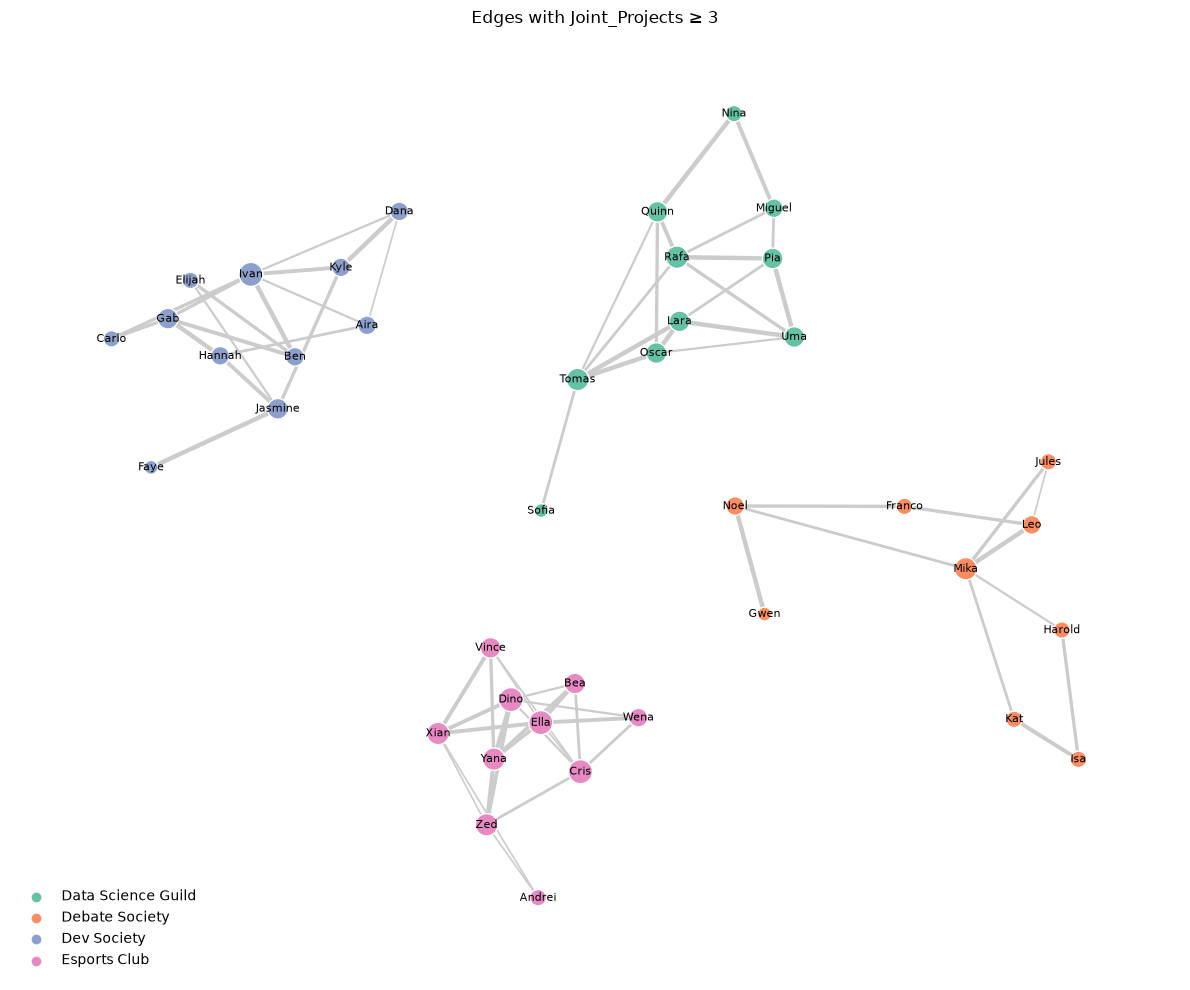

In [14]:
G3 = nx.Graph([(u, v, d) for u, v, d in G.edges(data=True) if d["Joint_Projects"] >= 3])
G3.add_nodes_from(G)
nx.set_node_attributes(G3, nx.get_node_attributes(G, "org"), "org")

within_w = [d["Joint_Projects"] for u, v, d in G.edges(data=True) if G.nodes[u]["org"] == G.nodes[v]["org"]]
cross_w = [d["Joint_Projects"] for u, v, d in G.edges(data=True) if G.nodes[u]["org"] != G.nodes[v]["org"]]
print(f"Edges kept: {G3.number_of_edges()} of {G.number_of_edges()} ({G.number_of_edges() - G3.number_of_edges()} removed)")
print(f"Density: {nx.density(G3):.4f} (original {nx.density(G):.4f})")
print("Components:", nx.number_connected_components(G3))
print(f"Within-organization weights: min {min(within_w)}, max {max(within_w)}")
print(f"Cross-organization weights:  min {min(cross_w)}, max {max(cross_w)}")
print("Cross-organization edges kept:", sum(w >= 3 for w in cross_w))
for comp in sorted(nx.connected_components(G3), key=lambda comp: (-len(comp), min(G.nodes[n]["org"] for n in comp))):
    print(f"  {len(comp):2} students — {', '.join(sorted({G.nodes[n]['org'] for n in comp}))}")

draw_net(G3, pos, "Edges with Joint_Projects ≥ 3")


### Report

The filtered graph has **69** edges (17 removed) and density **0.0885**. It has **4** components, and each component is exactly one organization:

- Dev Society — 11 students
- Data Science Guild — 10 students
- Esports Club — 10 students
- Debate Society — 9 students

### Interpret

Every project inside an organization has weight at least 3. Every cross-organization project has weight 1 or 2. The cutoff of 3 therefore deletes exactly the 17 bridges, and it deletes nothing inside the clubs. In the drawing, the dark cross-organization edges are gone and the four color groups no longer touch.

That is the weak-tie pattern. The ties that hold different groups together are the weak ones, and the strong ties sit inside groups. Someone who only saw this filtered picture would conclude that the four organizations never collaborate. The full graph says something else: the class is one connected network, and those light cross-organization projects are what hold it together. The threshold decides which of those two conclusions the picture supports.


## Q10. Community robustness

**Manipulate.** Louvain with seeds 1, 7, and 99, using `Joint_Projects` as the weight. The same three seeds with no weights. Greedy modularity, with the weight and without it.

**Report.** Report the number of communities in each run and whether the memberships match the four organizations.

**Interpret.** Why is it good practice to test community results with different seeds or algorithms before presenting them?


In [15]:
org_of = nx.get_node_attributes(G, "org")
org_partition = {frozenset(n for n, o in org_of.items() if o == group) for group in set(org_of.values())}

def describe(comms):
    comms = [set(c) for c in comms]
    match = {frozenset(c) for c in comms} == org_partition
    notes = []
    if not match:
        for c in comms:
            counts = pd.Series([org_of[n] for n in c]).value_counts()
            if len(counts) == 1:
                continue
            majority = counts.index[0]
            for name in sorted(n for n in c if org_of[n] != majority):
                notes.append(f"{name} ({org_of[name]}) grouped with {majority}")
    return len(comms), match, "; ".join(notes) if notes else "—"

# One weighted run, shown the same way as the demo: communities against home organization.
comms = nxcom.louvain_communities(G, weight="Joint_Projects", seed=1)
comm_of = {n: i for i, c in enumerate(comms) for n in c}
print("Communities found:", len(comms))
display(pd.crosstab(pd.Series(org_of, name="org"), pd.Series(comm_of, name="community")))

runs = []
for seed in (1, 7, 99):
    runs.append(("Louvain", seed, "Joint_Projects", *describe(nxcom.louvain_communities(G, weight="Joint_Projects", seed=seed))))
for seed in (1, 7, 99):
    runs.append(("Louvain", seed, "none", *describe(nxcom.louvain_communities(G, weight=None, seed=seed))))
runs.append(("Greedy modularity", "—", "Joint_Projects", *describe(nxcom.greedy_modularity_communities(G, weight="Joint_Projects"))))
runs.append(("Greedy modularity", "—", "none", *describe(nxcom.greedy_modularity_communities(G))))

pd.DataFrame(runs, columns=["Algorithm", "Seed", "Weight", "Communities", "Matches organizations", "If not, who moved"])


Communities found: 4


community,0,1,2,3
org,,,,
Data Science Guild,0,10,0,0
Debate Society,0,0,0,9
Dev Society,11,0,0,0
Esports Club,0,0,10,0


,Algorithm,Seed,Weight,Communities,Matches organizations,"If not, who moved"
0,Louvain,1,Joint_Projects,4,True,—
1,Louvain,7,Joint_Projects,4,True,—
2,Louvain,99,Joint_Projects,4,True,—
3,Louvain,1,none,4,True,—
4,Louvain,7,none,4,True,—
5,Louvain,99,none,4,True,—
6,Greedy modularity,—,Joint_Projects,4,True,—
7,Greedy modularity,—,none,4,False,Uma (Data Science Guild) grouped with Debate S...


### Report

| Run | Communities | Matches the four organizations? |
|---|---:|---|
| Louvain, weight = Joint_Projects, seeds 1, 7, and 99 | 4 every time | Yes. Each community is exactly one organization. |
| Louvain, no weights, seeds 1 and 7 | 4 | Yes |
| Louvain, no weights, seed 99 | 4 | No. Sofia (Data Science Guild) is placed with Esports Club. |
| Greedy modularity, weight = Joint_Projects | 4 | Yes |
| Greedy modularity, no weights | 4 | No. Uma (Data Science Guild) is placed with Debate Society. |

### Interpret

Louvain's search depends on the random seed, and more than one partition can score well on modularity. On the weighted graph the three seeds agree with each other and with greedy modularity, and all of them recover the four home organizations. That result is stable enough to present.

Dropping the weights makes the same question fragile. Seed 99 moves Sofia into Esports Club, and unweighted greedy modularity moves Uma into Debate Society. Both students sit on the boundary: Sofia has a project with Ella (Esports), and Uma has projects with Harold and Jules (Debate). A single run would hide those swaps. Trying a few seeds and a second algorithm shows which grouping holds up — here, the four organizations, once the strength of a tie is counted — and which students are close to switching.
